# `cleaned_answer` vs `parity_answer` — full metric comparison

Runs the paper's complete measurement framework over both versions of the explicit responses,
**before any fine-tuning**, to check whether the parity rewrites are actually better on the
metrics the audit reports — not just on the regex entity proxy used to gate the rewrite loop.

## Design

The High-literacy response is **byte-identical in both versions** (verified below), so it
serves as a shared reference and every difference is attributable to the rewrite.

| Family | Metric | Paper | Scope |
|---|---|---|---|
| Linguistic register | Flesch–Kincaid grade | §3.1, Eq. 1 | per response |
| | Average word count | §3.1 | per response |
| | ROUGE-Lsum P/R/F₁ | §3.1, Eq. 2 | vs High |
| Substantive content | Specific entity count | §3.2, App. C | per response |
| | Semantic loss `1 − cos` (BGE-M3) | §3.2, Eq. 3 | vs High |
| | NLI entailment (bidirectional) | §3.2, Eq. 4 | vs High |
| Posture | Info axis P(comprehensive & detailed) | §3.3, Eq. 6 | per response |
| | Style axis P(formal & professional) | §3.3, Eq. 6 | per response |

## Three questions, three test families

1. **Does stratification survive in each version?** Paired *t* on High>Mid, High>Low, Mid>Low
   plus repeated-measures one-way ANOVA with partial η², within each version.
   *We want this to stay true for FK and Style, and to weaken for the content metrics.*
2. **Did the rewrite change each metric?** Paired *t*, before vs after, at Mid and Low
   (High is degenerate — identical text).
3. **How far from perfect preservation?** One-sample *t* against μ₀=0 (semantic loss) and
   μ₀=1 (NLI entailment), as in Appendix B.3–B.4.

All tests are paired by event ID and Bonferroni-corrected within each metric family
(Eq. 9). Effect sizes use the paper's bands: 0.2 small · 0.5 medium · 0.8 large ·
1.2 very large · 2.0 huge; η²ₚ 0.01 / 0.06 / 0.14.

The statistical machinery lives in `src/paper_metrics.py` and is unit-tested against known
critical values and the `F = t²` identity for k=2.

> **Scope note.** This scores all 250 events. That is correct here — the question is whether
> the training targets are better, not whether a model generalises. Post-training evaluation
> must restrict to the 50 held-out events in `event_split.json`.

In [1]:
from pathlib import Path
import os, sys, json, gc, time, math

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from paper_metrics import (fk_grade, word_count, rouge_lsum,
                           one_sample_t, paired_t, rm_anova, bonferroni, sig,
                           d_label, eta_label, mean, sd)

DATA     = ROOT / "newly_generated_answers" / "explicit_answers_local_base.csv"
RESULTS  = ROOT / "results"
CACHE    = RESULTS / "metrics_cleaned_vs_parity.csv"
RESULTS.mkdir(parents=True, exist_ok=True)

LEVELS   = ["High Literacy", "Mid Literacy", "Low Literacy"]
VERSIONS = {"before": "cleaned_answer", "after": "parity_answer"}

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("data  :", DATA.name, "|", "found" if DATA.exists() else "MISSING")
print("device:", DEVICE)

data  : explicit_answers_local_base.csv | found
device: cuda


## 1. Build the comparison frame

In [2]:
raw = pd.read_csv(DATA)
wide = {(r["ID"], r["Literacy_Level"]): r for _, r in raw.iterrows()}
event_ids = sorted({r["ID"] for _, r in raw.iterrows()})

# High must be identical across versions, or the shared-reference design breaks
mismatch = [e for e in event_ids
            if wide[(e, "High Literacy")]["cleaned_answer"] != wide[(e, "High Literacy")]["parity_answer"]]
assert not mismatch, f"High differs in {len(mismatch)} events: {mismatch[:5]}"
print(f"High identical across versions in all {len(event_ids)} events -- shared reference is valid")

rows = []
for e in event_ids:
    ref = wide[(e, "High Literacy")]["cleaned_answer"]
    for lvl in LEVELS:
        src = wide[(e, lvl)]
        for ver, col in VERSIONS.items():
            rows.append({"event_id": e, "Domain": src["Domain"], "Topic": src["Topic"],
                         "level": lvl, "level_s": lvl.split()[0], "version": ver,
                         "text": str(src[col]), "reference": ref})
df = pd.DataFrame(rows)
print(f"frame: {len(df)} rows = {len(event_ids)} events x {len(LEVELS)} levels x {len(VERSIONS)} versions")

if CACHE.exists():
    cached = pd.read_csv(CACHE)
    keep = [c for c in cached.columns if c not in df.columns]
    if keep:
        df = df.merge(cached[["event_id", "level", "version"] + keep],
                      on=["event_id", "level", "version"], how="left")
        print(f"restored cached metrics: {keep}")


def save_cache():
    cols = [c for c in df.columns if c not in ("text", "reference")]
    df[cols].to_csv(CACHE, index=False)
    print(f"  cached -> {os.path.relpath(CACHE, ROOT)}")

High identical across versions in all 250 events -- shared reference is valid
frame: 1500 rows = 250 events x 3 levels x 2 versions


## 2. Linguistic register — FK grade, word count, ROUGE-Lsum

CPU only. ROUGE-Lsum uses the `rouge_score` package when installed so the numbers match the
paper's tooling; the fallback in `paper_metrics` implements the same union-LCS formula.

In [3]:
if "fk" not in df.columns:
    t0 = time.time()
    df["fk"] = df["text"].map(fk_grade)
    df["words"] = df["text"].map(word_count)

    try:
        from rouge_score import rouge_scorer
        scorer = rouge_scorer.RougeScorer(["rougeLsum"], use_stemmer=True)
        def _r(row):
            if row["level"] == "High Literacy":
                return pd.Series({"rouge_p": np.nan, "rouge_r": np.nan, "rouge_f1": np.nan})
            s = scorer.score(row["reference"], row["text"])["rougeLsum"]
            return pd.Series({"rouge_p": s.precision, "rouge_r": s.recall, "rouge_f1": s.fmeasure})
        impl = "rouge_score package"
    except ImportError:
        def _r(row):
            if row["level"] == "High Literacy":
                return pd.Series({"rouge_p": np.nan, "rouge_r": np.nan, "rouge_f1": np.nan})
            s = rouge_lsum(row["reference"], row["text"])
            return pd.Series({"rouge_p": s["precision"], "rouge_r": s["recall"], "rouge_f1": s["f1"]})
        impl = "paper_metrics fallback"

    df[["rouge_p", "rouge_r", "rouge_f1"]] = df.apply(_r, axis=1)
    print(f"register metrics done in {time.time()-t0:.0f}s (ROUGE via {impl})")
    save_cache()

print(df.groupby(["version", "level_s"])[["fk", "words", "rouge_f1"]]
        .mean().round(2).to_string())

register metrics done in 10s (ROUGE via rouge_score package)
  cached -> results/metrics_cleaned_vs_parity.csv
                    fk   words  rouge_f1
version level_s                         
after   High     15.81  459.31       NaN
        Low       6.32  166.91      0.39
        Mid       8.06  192.86      0.47
before  High     15.81  459.31       NaN
        Low       6.02  195.18      0.29
        Mid       6.74  197.18      0.30


## 3. Specific entity count

The paper uses Gemini 3.1 Flash Lite with a 17-category rubric at temperature 0 (Appendix C).
Set `GEMINI_API_KEY` in a `.env` to reproduce that exactly. Without a key this falls back to
the regex proxy — **which is the same signal that gated the rewrite loop**, so it is
circular here and must be labelled as such in any write-up. The regex numbers are a sanity
check, not a result.

In [4]:
USE_GEMINI = bool(os.environ.get("GEMINI_API_KEY"))

if "entities" not in df.columns:
    if USE_GEMINI:
        import re
        import google.generativeai as genai
        genai.configure(api_key=os.environ["GEMINI_API_KEY"])
        gem = genai.GenerativeModel("gemini-3.1-flash-lite")
        RUBRIC = (
            "Count the distinct specific, named, dated or quantified real-world entities in the "
            "text. Categories: law/policy names; section or article references; organisation "
            "names; specific penalties; monetary amounts; durations and deadlines; quantitative "
            "measures and thresholds; scientific terms; named standards and protocols; case-law "
            "citations; medical conditions; real-person names; standalone dates; geographic "
            "references; technical identifiers; numeric safety/approval thresholds; other "
            "specific real-world entities. Count each distinct entity at most once regardless of "
            "how often or in what form it appears. Exclude generic references such as 'the law'. "
            "Return ONLY a JSON object: {\"count\": <int>, \"entities\": [<string>, ...]}\n\nTEXT:\n"
        )
        def extract(text):
            for _ in range(3):
                try:
                    r = gem.generate_content(RUBRIC + text,
                                             generation_config={"temperature": 0})
                    m = re.search(r"\{.*\}", r.text, re.S)
                    return int(json.loads(m.group(0))["count"])
                except Exception:
                    time.sleep(2)
            return np.nan
        df["entities"] = [extract(t) for t in df["text"]]
        ENTITY_SOURCE = "Gemini 3.1 Flash Lite rubric extractor (paper Appendix C)"
    else:
        from parity_rewrite import entity_proxy
        df["entities"] = df["text"].map(lambda t: len(entity_proxy(t)))
        ENTITY_SOURCE = "regex proxy -- CIRCULAR with the rewrite gate, not a result"
    print(ENTITY_SOURCE)
    save_cache()
else:
    ENTITY_SOURCE = "Gemini rubric" if USE_GEMINI else "regex proxy (circular)"

print(f"\nsource: {ENTITY_SOURCE}")
print(df.groupby(["version", "level_s"])["entities"].mean().round(2).to_string())

regex proxy -- CIRCULAR with the rewrite gate, not a result
  cached -> results/metrics_cleaned_vs_parity.csv

source: regex proxy -- CIRCULAR with the rewrite gate, not a result
version  level_s
after    High       5.28
         Low        3.54
         Mid        3.57
before   High       5.28
         Low        1.98
         Mid        2.06


## 4. Semantic loss — BGE-M3

`SimLoss = 1 − cos(e_High, e_target)` (Eq. 3). 0.0 is perfect preservation of the
High-literacy content in embedding space; larger values mean more conceptual drift.

In [5]:
if "sem_loss" not in df.columns:
    from sentence_transformers import SentenceTransformer
    emb_model = SentenceTransformer("BAAI/bge-m3", device=DEVICE)

    texts = list(dict.fromkeys(df["text"].tolist() + df["reference"].tolist()))
    t0 = time.time()
    vecs = emb_model.encode(texts, batch_size=8, normalize_embeddings=True,
                            show_progress_bar=True, convert_to_numpy=True)
    lut = {t: v for t, v in zip(texts, vecs)}
    print(f"embedded {len(texts)} unique texts in {(time.time()-t0)/60:.1f} min")

    df["sem_loss"] = [
        np.nan if lvl == "High Literacy" else float(1.0 - np.dot(lut[t], lut[r]))
        for lvl, t, r in zip(df["level"], df["text"], df["reference"])
    ]
    del emb_model, vecs, lut
    gc.collect(); torch.cuda.empty_cache()
    save_cache()

print(df[df.level != "High Literacy"].groupby(["version", "level_s"])["sem_loss"]
        .agg(["mean", "std"]).round(4).to_string())

/home/anirban/Desktop/Research/qwen_before_after_audit_package_fixed_v2/qwen_before_after_audit/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 155/155 [00:33<00:00,  4.58it/s]


embedded 1239 unique texts in 0.6 min
  cached -> results/metrics_cleaned_vs_parity.csv
                   mean     std
version level_s                
after   Low      0.1136  0.0304
        Mid      0.0966  0.0259
before  Low      0.1666  0.0407
        Mid      0.1523  0.0341


## 5. NLI entailment — ModernCE-large-NLI

Bidirectional, as in Eq. 4: `NLI_c = ½(P_c(High, X) + P_c(X, High))`.

**Label order is read from the model config at run time, not hardcoded.** The model card's
usage snippet says `['contradiction', 'entailment', 'neutral']` while its own `config.json`
declares `{0: entailment, 1: neutral, 2: contradiction}`. Trusting the README would report
*neutral* as entailment and silently invert the headline metric. The assertion below fails
loudly if the config ever changes.

In [6]:
if "nli_ent" not in df.columns:
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    NLI_ID = "dleemiller/ModernCE-large-nli"
    nli_tok = AutoTokenizer.from_pretrained(NLI_ID)
    nli = AutoModelForSequenceClassification.from_pretrained(
        NLI_ID, dtype=torch.float32).to(DEVICE).eval()

    id2label = {int(k): v.lower() for k, v in nli.config.id2label.items()}
    print("resolved label order from config:", id2label)
    assert set(id2label.values()) == {"entailment", "neutral", "contradiction"}, id2label
    IDX = {v: k for k, v in id2label.items()}

    MAXLEN = min(getattr(nli.config, "max_position_embeddings", 2048), 2048)
    print(f"max sequence length: {MAXLEN} tokens (pairs longer than this are truncated)")

    pairs = df[df.level != "High Literacy"].index.tolist()

    def batched_probs(premises, hypotheses, bs=8):
        out = []
        for i in range(0, len(premises), bs):
            enc = nli_tok(premises[i:i+bs], hypotheses[i:i+bs], return_tensors="pt",
                          padding=True, truncation=True, max_length=MAXLEN).to(DEVICE)
            with torch.inference_mode():
                p = torch.softmax(nli(**enc).logits, dim=-1)
            out.append(p.float().cpu().numpy())
            if (i // bs) % 20 == 0:
                print(f"    {i}/{len(premises)}", flush=True)
        return np.concatenate(out) if out else np.zeros((0, 3))

    hi = df.loc[pairs, "reference"].tolist()
    tx = df.loc[pairs, "text"].tolist()
    t0 = time.time()
    print("  forward direction (High -> X)")
    fwd = batched_probs(hi, tx)
    print("  reverse direction (X -> High)")
    rev = batched_probs(tx, hi)
    avg = (fwd + rev) / 2.0
    print(f"  {2*len(pairs)} pairs in {(time.time()-t0)/60:.1f} min")

    for name in ("ent", "neu", "con"):
        df[f"nli_{name}"] = np.nan
    df.loc[pairs, "nli_ent"] = avg[:, IDX["entailment"]]
    df.loc[pairs, "nli_neu"] = avg[:, IDX["neutral"]]
    df.loc[pairs, "nli_con"] = avg[:, IDX["contradiction"]]

    del nli; gc.collect(); torch.cuda.empty_cache()
    save_cache()

print(df[df.level != "High Literacy"].groupby(["version", "level_s"])[["nli_ent", "nli_neu", "nli_con"]]
        .mean().round(3).to_string())

Loading weights: 100%|██████████| 174/174 [00:00<00:00, 2524.37it/s]


resolved label order from config: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
max sequence length: 2048 tokens (pairs longer than this are truncated)
  forward direction (High -> X)
    0/1000
    160/1000
    320/1000
    480/1000
    640/1000
    800/1000
    960/1000
  reverse direction (X -> High)
    0/1000
    160/1000
    320/1000
    480/1000
    640/1000
    800/1000
    960/1000
  2000 pairs in 3.6 min
  cached -> results/metrics_cleaned_vs_parity.csv
                 nli_ent  nli_neu  nli_con
version level_s                           
after   Low        0.003    0.781    0.216
        Mid        0.001    0.828    0.170
before  Low        0.038    0.616    0.346
        Mid        0.046    0.663    0.291


## 6. Posture axes — bge-m3-zeroshot-v2.0

Two independent binary axes (Eq. 6). The two label probabilities on an axis are
complementary, so only P(ℓ₁) is reported.

In [7]:
if "info_p" not in df.columns:
    from transformers import pipeline
    zs = pipeline("zero-shot-classification", model="MoritzLaurer/bge-m3-zeroshot-v2.0",
                  device=0 if DEVICE == "cuda" else -1)

    AXES = {"info_p":  ["comprehensive and detailed", "minimal and simplified"],
            "style_p": ["formal and professional", "casual and conversational"]}

    texts = df["text"].tolist()
    for col, labels in AXES.items():
        t0 = time.time()
        scores = []
        for i in range(0, len(texts), 16):
            out = zs(texts[i:i+16], candidate_labels=labels, multi_label=False)
            out = out if isinstance(out, list) else [out]
            for o in out:
                scores.append(o["scores"][o["labels"].index(labels[0])])
            if (i // 16) % 10 == 0:
                print(f"  {col} {i}/{len(texts)}", flush=True)
        df[col] = scores
        print(f"  {col} ('{labels[0]}') done in {(time.time()-t0)/60:.1f} min")

    del zs; gc.collect(); torch.cuda.empty_cache()
    save_cache()

print(df.groupby(["version", "level_s"])[["info_p", "style_p"]].mean().round(3).to_string())

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 3878.78it/s]


  info_p 0/1500


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  info_p 160/1500
  info_p 320/1500
  info_p 480/1500
  info_p 640/1500
  info_p 800/1500
  info_p 960/1500
  info_p 1120/1500
  info_p 1280/1500
  info_p 1440/1500
  info_p ('comprehensive and detailed') done in 0.4 min
  style_p 0/1500
  style_p 160/1500
  style_p 320/1500
  style_p 480/1500
  style_p 640/1500
  style_p 800/1500
  style_p 960/1500
  style_p 1120/1500
  style_p 1280/1500
  style_p 1440/1500
  style_p ('formal and professional') done in 0.4 min
  cached -> results/metrics_cleaned_vs_parity.csv
                 info_p  style_p
version level_s                 
after   High      0.719    0.963
        Low       0.470    0.856
        Mid       0.482    0.874
before  High      0.719    0.963
        Low       0.016    0.082
        Mid       0.019    0.116


## 7. Descriptive table

In [8]:
PER_RESPONSE = ["fk", "words", "entities", "info_p", "style_p"]
PAIRWISE     = ["rouge_f1", "sem_loss", "nli_ent"]
ALL_METRICS  = PER_RESPONSE + PAIRWISE

NICE = {"fk": "FK grade", "words": "word count", "entities": "entity count",
        "info_p": "Info P(comprehensive)", "style_p": "Style P(formal)",
        "rouge_f1": "ROUGE-Lsum F1", "sem_loss": "semantic loss", "nli_ent": "NLI entailment"}

tab = (df.groupby(["version", "level_s"])[ALL_METRICS].mean()
         .reindex(pd.MultiIndex.from_product([["before", "after"], ["High", "Mid", "Low"]],
                                             names=["version", "level_s"])))
print(tab.round(3).to_string())

def series(metric, version, level):
    s = df[(df.version == version) & (df.level_s == level)].sort_values("event_id")[metric]
    return s.tolist()

                     fk    words  entities  info_p  style_p  rouge_f1  sem_loss  nli_ent
version level_s                                                                         
before  High     15.809  459.312     5.276   0.719    0.963       NaN       NaN      NaN
        Mid       6.736  197.184     2.060   0.019    0.116     0.303     0.152    0.046
        Low       6.019  195.180     1.980   0.016    0.082     0.289     0.167    0.038
after   High     15.809  459.312     5.276   0.719    0.963       NaN       NaN      NaN
        Mid       8.061  192.860     3.568   0.482    0.874     0.467     0.097    0.001
        Low       6.321  166.912     3.536   0.470    0.856     0.390     0.114    0.003


## 8. Question 1 — does stratification survive within each version?

Paired *t* (one-tailed, higher level expected greater) on each adjacent contrast, plus a
repeated-measures one-way ANOVA across the three levels. Bonferroni k = 3 contrasts × 2
versions = 6 for per-response metrics; k = 1 × 2 = 2 for the pairwise metrics, which have
only the High–Mid vs High–Low contrast.

**Read it as a dissociation.** FK and Style *should* still stratify in the `after` column.
Entity count, NLI entailment, semantic loss and Info *should* stratify less than they did.

In [9]:
ALPHA = 0.05
K_PER_RESPONSE, K_PAIRWISE = 6, 2

print(f"Bonferroni: per-response alpha={bonferroni(ALPHA,K_PER_RESPONSE):.5f} (k={K_PER_RESPONSE}) | "
      f"pairwise alpha={bonferroni(ALPHA,K_PAIRWISE):.5f} (k={K_PAIRWISE})\n")

# Direction of the alternative hypothesis. For the pairwise metrics the level *is* the
# candidate and the score is already relative to High, so the only contrast is Mid vs Low --
# and semantic loss runs the other way: LOWER means closer to the reference, so the
# hypothesis is Low > Mid, not Mid > Low. Getting this backwards reports a real effect as ns.
HIGHER_IS_CLOSER = {"rouge_f1": True, "nli_ent": True, "sem_loss": False}

for metric in ALL_METRICS:
    pairwise = metric in PAIRWISE
    a_corr = bonferroni(ALPHA, K_PAIRWISE if pairwise else K_PER_RESPONSE)
    if pairwise:
        contrasts = [("Mid", "Low")] if HIGHER_IS_CLOSER[metric] else [("Low", "Mid")]
    else:
        contrasts = [("High", "Mid"), ("High", "Low"), ("Mid", "Low")]

    print(f"--- {NICE[metric]} ---")
    for ver in ("before", "after"):
        for hi, lo in contrasts:
            a, b = series(metric, ver, hi), series(metric, ver, lo)
            r = paired_t(a, b, tail="greater")
            print(f"  {ver:6s} {hi:>4s}>{lo:<4s}  mean {r['mean_a']:8.3f} vs {r['mean_b']:8.3f}  "
                  f"t={r['t']:8.2f}  p={r['p']:.2e}  d={r['d']:6.2f} ({r['d_label']:10s}) {sig(r['p'],a_corr)}")
        if not pairwise:
            an = rm_anova([series(metric, ver, l) for l in ["High", "Mid", "Low"]])
            print(f"  {ver:6s} RM-ANOVA    F({an['df1']},{an['df2']})={an['F']:.1f}  "
                  f"p={an['p']:.2e}  eta_p2={an['eta_p2']:.3f} ({an['eta_label']})")
    print()

Bonferroni: per-response alpha=0.00833 (k=6) | pairwise alpha=0.02500 (k=2)

--- FK grade ---
  before High>Mid   mean   15.809 vs    6.736  t=   62.79  p=5.81e-155  d=  3.97 (huge      ) sig
  before High>Low   mean   15.809 vs    6.019  t=   67.10  p=9.38e-162  d=  4.24 (huge      ) sig
  before  Mid>Low   mean    6.736 vs    6.019  t=    9.87  p=6.80e-20  d=  0.62 (medium    ) sig
  before RM-ANOVA    F(2,498)=3766.2  p=2.14e-301  eta_p2=0.938 (large)
  after  High>Mid   mean   15.809 vs    8.061  t=   48.33  p=8.15e-129  d=  3.06 (huge      ) sig
  after  High>Low   mean   15.809 vs    6.321  t=   57.03  p=3.08e-145  d=  3.61 (huge      ) sig
  after   Mid>Low   mean    8.061 vs    6.321  t=   20.91  p=4.89e-57  d=  1.32 (very large) sig
  after  RM-ANOVA    F(2,498)=2538.2  p=6.41e-262  eta_p2=0.911 (large)

--- word count ---
  before High>Mid   mean  459.312 vs  197.184  t=   35.94  p=7.96e-101  d=  2.27 (huge      ) sig
  before High>Low   mean  459.312 vs  195.180  t=   35.03 

## 9. Question 2 — did the rewrite move the metric?

Paired *t*, before vs after, at Mid and Low. Two-tailed: we have a directional expectation for
the content metrics but not for every metric, and a two-tailed test is the honest default.
High is excluded — the text is identical, so the difference is exactly zero by construction.

Bonferroni k = 2 (Mid, Low) within each metric.

In [10]:
a_corr = bonferroni(ALPHA, 2)
WANT = {"entities": "up", "nli_ent": "up", "info_p": "up", "rouge_f1": "up",
        "sem_loss": "down", "fk": "should NOT rise much", "style_p": "should NOT rise much",
        "words": "free"}

print(f"paired t, before vs after, alpha_corr={a_corr:.5f} (k=2)\n")
print(f"  {'metric':22s}{'level':6s}{'before':>9s}{'after':>9s}{'delta':>9s}{'t':>9s}{'p':>11s}{'d':>8s}  {'':10s} want")
for metric in ALL_METRICS:
    for lvl in (["Mid", "Low"]):
        b, a = series(metric, "before", lvl), series(metric, "after", lvl)
        r = paired_t(a, b, tail="two")          # after - before
        print(f"  {NICE[metric]:22s}{lvl:6s}{r['mean_b']:9.3f}{r['mean_a']:9.3f}{r['mean_diff']:+9.3f}"
              f"{r['t']:9.2f}{r['p']:11.2e}{r['d']:8.2f}  {r['d_label']:10s} {WANT[metric]}"
              f"  {sig(r['p'], a_corr)}")

paired t, before vs after, alpha_corr=0.02500 (k=2)

  metric                level    before    after    delta        t          p       d             want
  FK grade              Mid       6.736    8.061   +1.325     9.86   1.41e-19    0.62  medium     should NOT rise much  sig
  FK grade              Low       6.019    6.321   +0.302     2.46   1.46e-02    0.16  negligible should NOT rise much  sig
  word count            Mid     197.184  192.860   -4.324    -1.26   2.10e-01   -0.08  negligible free  ns
  word count            Low     195.180  166.912  -28.268    -8.47   2.11e-15   -0.54  medium     free  sig
  entity count          Mid       2.060    3.568   +1.508     9.79   2.43e-19    0.62  medium     up  sig
  entity count          Low       1.980    3.536   +1.556    10.08   2.95e-20    0.64  medium     up  sig
  Info P(comprehensive) Mid       0.019    0.482   +0.463    39.14  2.31e-108    2.48  huge       up  sig
  Info P(comprehensive) Low       0.016    0.470   +0.454    38

## 10. Question 3 — distance from perfect preservation

One-sample *t* against the paper's reference values: μ₀ = 0 for semantic loss (identical
content) and μ₀ = 1 for NLI entailment (full mutual entailment). This is the Appendix B.3–B.4
test. A rewrite that truly preserved content would drive both toward their reference and
shrink |d|.

Bonferroni k = 4 (2 versions × 2 levels).

In [11]:
a_corr = bonferroni(ALPHA, 4)
print(f"one-sample t, alpha_corr={a_corr:.5f} (k=4)\n")
for metric, mu0, tail in [("sem_loss", 0.0, "greater"), ("nli_ent", 1.0, "less")]:
    print(f"--- {NICE[metric]} vs mu0={mu0} ---")
    for ver in ("before", "after"):
        for lvl in ("Mid", "Low"):
            r = one_sample_t(series(metric, ver, lvl), mu0, tail=tail)
            print(f"  {ver:6s} {lvl:4s}  mean {r['mean']:.4f} (sd {r['sd']:.4f})  "
                  f"t={r['t']:9.2f}  p={r['p']:.2e}  d={r['d']:7.2f} ({r['d_label']}) {sig(r['p'],a_corr)}")
    print()

one-sample t, alpha_corr=0.01250 (k=4)

--- semantic loss vs mu0=0.0 ---
  before Mid   mean 0.1523 (sd 0.0341)  t=    70.61  p=5.39e-167  d=   4.47 (huge) sig
  before Low   mean 0.1666 (sd 0.0407)  t=    64.69  p=5.21e-158  d=   4.09 (huge) sig
  after  Mid   mean 0.0966 (sd 0.0259)  t=    59.00  p=1.17e-148  d=   3.73 (huge) sig
  after  Low   mean 0.1136 (sd 0.0304)  t=    59.15  p=6.43e-149  d=   3.74 (huge) sig

--- NLI entailment vs mu0=1.0 ---
  before Mid   mean 0.0457 (sd 0.0621)  t=  -242.80  p=0.00e+00  d= -15.36 (huge) sig
  before Low   mean 0.0381 (sd 0.0684)  t=  -222.49  p=0.00e+00  d= -14.07 (huge) sig
  after  Mid   mean 0.0014 (sd 0.0060)  t= -2646.15  p=0.00e+00  d=-167.36 (huge) sig
  after  Low   mean 0.0026 (sd 0.0122)  t= -1290.02  p=0.00e+00  d= -81.59 (huge) sig



## 11. Verdict

In [12]:
def delta(metric, lvl):
    r = paired_t(series(metric, "after", lvl), series(metric, "before", lvl), tail="two")
    return r["mean_diff"], r["p"], r["d"]

print("Content metrics -- want these to improve:")
for m, direction in [("entities", +1), ("nli_ent", +1), ("info_p", +1),
                     ("rouge_f1", +1), ("sem_loss", -1)]:
    verdict = []
    for lvl in ("Mid", "Low"):
        dm, p, d = delta(m, lvl)
        good = (dm * direction) > 0 and p < 0.025
        verdict.append(f"{lvl} {dm:+.3f} {'OK' if good else 'no'}")
    print(f"  {NICE[m]:22s} {' | '.join(verdict)}")

print("\nRegister metrics -- want these to KEEP descending High>Mid>Low:")
for m in ("fk", "style_p"):
    for ver in ("before", "after"):
        means = [np.mean(series(m, ver, l)) for l in ("High", "Mid", "Low")]
        mono = means[0] > means[1] > means[2]
        print(f"  {NICE[m]:22s} {ver:6s} {means[0]:7.2f} > {means[1]:7.2f} > {means[2]:7.2f}   "
              f"{'monotone' if mono else 'NOT MONOTONE -- adaptation lost'}")

print(f"\nEntity source: {ENTITY_SOURCE}")

Content metrics -- want these to improve:
  entity count           Mid +1.508 OK | Low +1.556 OK
  NLI entailment         Mid -0.044 no | Low -0.035 no
  Info P(comprehensive)  Mid +0.463 OK | Low +0.454 OK
  ROUGE-Lsum F1          Mid +0.164 OK | Low +0.101 OK
  semantic loss          Mid -0.056 OK | Low -0.053 OK

Register metrics -- want these to KEEP descending High>Mid>Low:
  FK grade               before   15.81 >    6.74 >    6.02   monotone
  FK grade               after    15.81 >    8.06 >    6.32   monotone
  Style P(formal)        before    0.96 >    0.12 >    0.08   monotone
  Style P(formal)        after     0.96 >    0.87 >    0.86   monotone

Entity source: regex proxy -- CIRCULAR with the rewrite gate, not a result


## 12. Distributions

Box plots per metric, literacy level on the x-axis, version as the two series — the same
form as the paper's Figures 1–5. Colours are the two validated categorical slots; identity is
carried by a legend as well as by hue.

saved results/cleaned_vs_parity.png


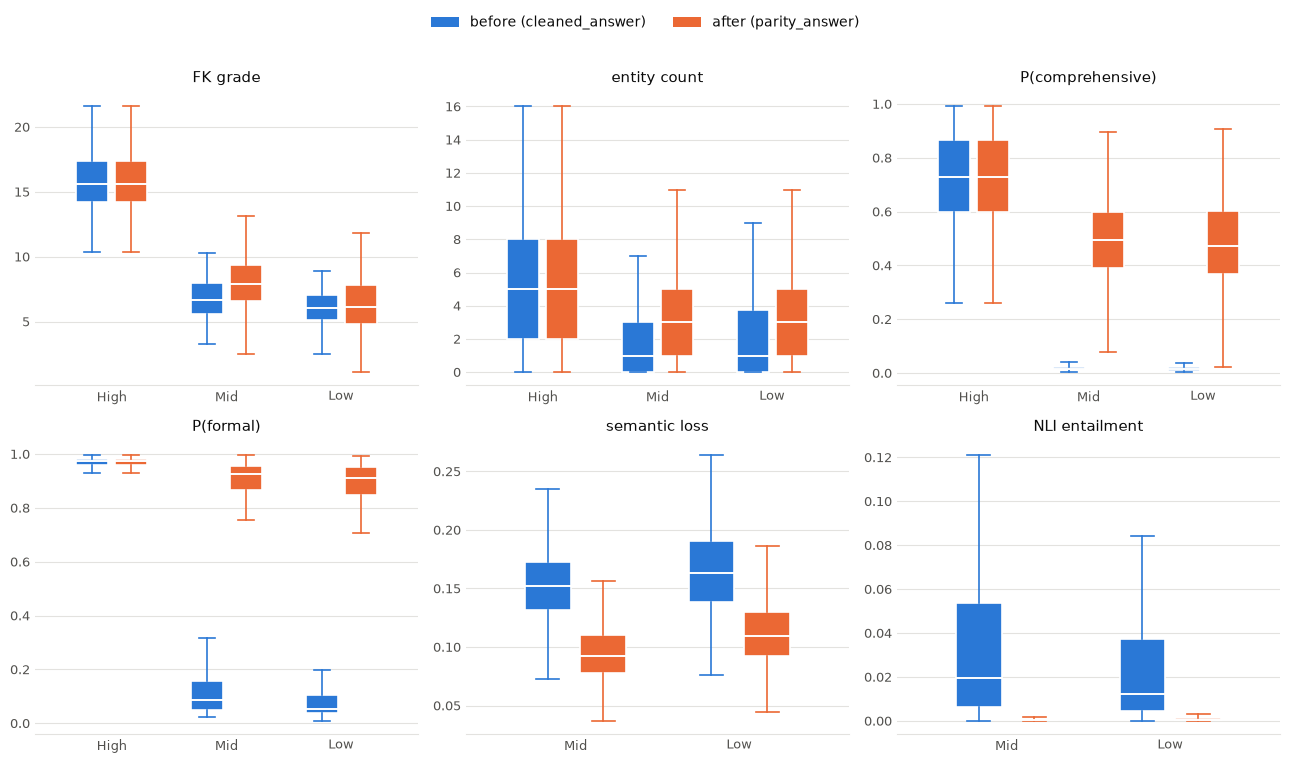

In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

BEFORE, AFTER = "#2a78d6", "#eb6834"     # validated categorical slots 1 and 2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e3e2df"

PANELS = [("fk", "FK grade"), ("entities", "entity count"), ("info_p", "P(comprehensive)"),
          ("style_p", "P(formal)"), ("sem_loss", "semantic loss"), ("nli_ent", "NLI entailment")]

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, (metric, title) in zip(axes.ravel(), PANELS):
    levels = ["Mid", "Low"] if metric in PAIRWISE else ["High", "Mid", "Low"]
    pos, ticks = [], []
    for i, lvl in enumerate(levels):
        for j, (ver, colour) in enumerate((("before", BEFORE), ("after", AFTER))):
            data = [x for x in series(metric, ver, lvl) if not (isinstance(x, float) and math.isnan(x))]
            p = i * 1.0 + (j - 0.5) * 0.34
            bp = ax.boxplot([data], positions=[p], widths=0.28, patch_artist=True,
                            showfliers=False, medianprops=dict(color="white", linewidth=1.4),
                            whiskerprops=dict(color=colour, linewidth=1.2),
                            capprops=dict(color=colour, linewidth=1.2),
                            boxprops=dict(facecolor=colour, edgecolor="white", linewidth=1.2))
            pos.append(p)
        ticks.append(i * 1.0)
    ax.set_xticks(ticks); ax.set_xticklabels(levels, color=INK)
    ax.set_title(title, color=INK, fontsize=11, pad=8)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0, labelsize=9)

fig.legend(handles=[Patch(facecolor=BEFORE, label="before (cleaned_answer)"),
                    Patch(facecolor=AFTER,  label="after (parity_answer)")],
           loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.02),
           labelcolor=INK)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(RESULTS / "cleaned_vs_parity.png", dpi=160, bbox_inches="tight",
            facecolor="white")
print("saved", os.path.relpath(RESULTS / "cleaned_vs_parity.png", ROOT))
plt.show()

## 13. Next

* If the content metrics improved significantly **and** FK/Style still descend, the parity
  targets are validated and `00c_train_parity.ipynb` is worth running.
* If entity count improved only on the regex proxy, get a `GEMINI_API_KEY` and re-run §3
  before claiming anything — the proxy gated the rewrite, so it cannot also be its evidence.
* If FK rose sharply at Low, consider raising `MIN_COVERAGE` in training (fewer but cleaner
  targets) or regenerating with a stronger words-per-sentence instruction.
* The full metric table is cached at `results/metrics_cleaned_vs_parity.csv`; the same code
  runs unchanged on the post-training regeneration, restricted to the held-out events.